In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.decomposition import PCA

In [7]:
df = pd.read_csv(r"C:\Users\Krutika Shivanand\Downloads\StudentPerformanceFactors.csv")

In [8]:
print("Original Dataset:")
print(df.head())

Original Dataset:
   Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0             23          84                  Low                High   
1             19          64                  Low              Medium   
2             24          98               Medium              Medium   
3             29          89                  Low              Medium   
4             19          92               Medium              Medium   

  Extracurricular_Activities  Sleep_Hours  Previous_Scores Motivation_Level  \
0                         No            7               73              Low   
1                         No            8               59              Low   
2                        Yes            7               91           Medium   
3                        Yes            8               98           Medium   
4                        Yes            6               65           Medium   

  Internet_Access  Tutoring_Sessions Family_Income Teacher_Quality  

In [9]:
print("\nDataset Shape:")
print(df.shape)


Dataset Shape:
(6607, 20)


In [10]:
print("\nColumn Names:")
print(df.columns)


Column Names:
Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='str')


In [11]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64


In [13]:
for column in df.select_dtypes(include=["object", "str"]).columns:
    df[column] = df[column].fillna(df[column].mode()[0])

In [14]:
for column in df.select_dtypes(include=np.number).columns:
    df[column] = df[column].fillna(df[column].median())

In [15]:
print("\nMissing Values After Handling:")
print(df.isnull().sum().sum())


Missing Values After Handling:
0


In [16]:
X = df.drop(columns=["Exam_Score"])
y = df["Exam_Score"]

In [17]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [18]:
print("\nEncoded Dataset:")
print(X.head())


Encoded Dataset:
   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0             23          84            7               73                  0   
1             19          64            8               59                  2   
2             24          98            7               91                  2   
3             29          89            8               98                  1   
4             19          92            6               65                  3   

   Physical_Activity  Parental_Involvement_Low  Parental_Involvement_Medium  \
0                  3                         1                            0   
1                  4                         1                            0   
2                  4                         0                            1   
3                  4                         1                            0   
4                  4                         0                            1   

   Access_to_Resourc

In [19]:
normalizer = MinMaxScaler()
normalized_data = normalizer.fit_transform(X)

In [20]:
normalized_df = pd.DataFrame(
    normalized_data,
    columns=X.columns
)

In [21]:
print("\nNormalized Dataset:")
print(normalized_df.head().round(2))


Normalized Dataset:
   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0           0.51        0.60         0.50             0.46               0.00   
1           0.42        0.10         0.67             0.18               0.25   
2           0.53        0.95         0.50             0.82               0.25   
3           0.65        0.73         0.67             0.96               0.12   
4           0.42        0.80         0.33             0.30               0.38   

   Physical_Activity  Parental_Involvement_Low  Parental_Involvement_Medium  \
0               0.50                       1.0                          0.0   
1               0.67                       1.0                          0.0   
2               0.67                       0.0                          1.0   
3               0.67                       1.0                          0.0   
4               0.67                       0.0                          1.0   

   Access_to_Reso

In [30]:
scaler = StandardScaler()
standardized_data = scaler.fit_transform(X)
standardized_df = pd.DataFrame(
    standardized_data,
    columns=X.columns
)
print("\nStandardized Dataset:")
print(standardized_df.head().round(2))


Standardized Dataset:
   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0           0.50        0.35        -0.02            -0.14              -1.21   
1          -0.16       -1.38         0.66            -1.12               0.41   
2           0.67        1.56        -0.02             1.11               0.41   
3           1.51        0.78         0.66             1.59              -0.40   
4          -0.16        1.04        -0.70            -0.70               1.22   

   Physical_Activity  Parental_Involvement_Low  Parental_Involvement_Medium  \
0               0.03                      1.99                        -1.02   
1               1.00                      1.99                        -1.02   
2               1.00                     -0.50                         0.98   
3               1.00                      1.99                        -1.02   
4               1.00                     -0.50                         0.98   

   Access_to_Re

In [34]:
print("\nMean of Standardized Features:")
print(standardized_df.mean().round(2))


Mean of Standardized Features:
Hours_Studied                           -0.0
Attendance                              -0.0
Sleep_Hours                             -0.0
Previous_Scores                          0.0
Tutoring_Sessions                        0.0
Physical_Activity                       -0.0
Parental_Involvement_Low                -0.0
Parental_Involvement_Medium              0.0
Access_to_Resources_Low                 -0.0
Access_to_Resources_Medium               0.0
Extracurricular_Activities_Yes           0.0
Motivation_Level_Low                     0.0
Motivation_Level_Medium                 -0.0
Internet_Access_Yes                     -0.0
Family_Income_Low                        0.0
Family_Income_Medium                     0.0
Teacher_Quality_Low                     -0.0
Teacher_Quality_Medium                   0.0
School_Type_Public                       0.0
Peer_Influence_Neutral                   0.0
Peer_Influence_Positive                 -0.0
Learning_Disabilities_Y

In [33]:
print("\nStandard Deviation of Standardized Features:")
print(standardized_df.std(ddof=0).round(2))


Standard Deviation of Standardized Features:
Hours_Studied                            1.0
Attendance                               1.0
Sleep_Hours                              1.0
Previous_Scores                          1.0
Tutoring_Sessions                        1.0
Physical_Activity                        1.0
Parental_Involvement_Low                 1.0
Parental_Involvement_Medium              1.0
Access_to_Resources_Low                  1.0
Access_to_Resources_Medium               1.0
Extracurricular_Activities_Yes           1.0
Motivation_Level_Low                     1.0
Motivation_Level_Medium                  1.0
Internet_Access_Yes                      1.0
Family_Income_Low                        1.0
Family_Income_Medium                     1.0
Teacher_Quality_Low                      1.0
Teacher_Quality_Medium                   1.0
School_Type_Public                       1.0
Peer_Influence_Neutral                   1.0
Peer_Influence_Positive                  1.0
Learning_

In [37]:
pca = PCA(n_components=2)
pca_data = pca.fit_transform(standardized_data)
pca_df = pd.DataFrame(
    pca_data,
    columns=["Principal_Component_1", "Principal_Component_2"]
)
print("\nPCA Transformed Dataset:")
print(pca_df.head().round(2))


PCA Transformed Dataset:
   Principal_Component_1  Principal_Component_2
0                   0.20                   0.25
1                   1.90                  -1.82
2                  -1.92                  -0.51
3                   1.30                  -0.40
4                  -1.97                  -0.31


In [38]:
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_.round(4))


Explained Variance Ratio:
[0.068  0.0627]


In [39]:
print("\nTotal Variance Retained:")
print(round(pca.explained_variance_ratio_.sum() * 100, 2), "%")


Total Variance Retained:
13.07 %


In [40]:
plt.figure(figsize=(8, 5))

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

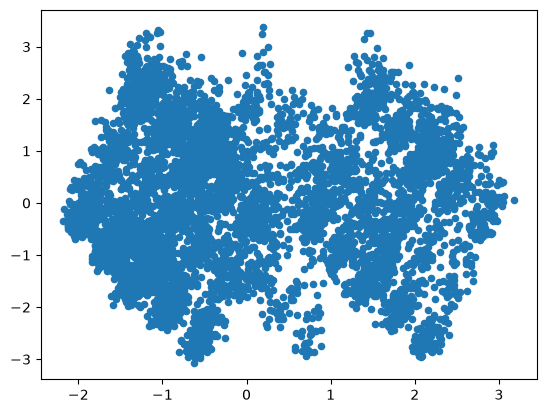

In [41]:
plt.scatter(
    pca_df["Principal_Component_1"],
    pca_df["Principal_Component_2"],
    s=20
)

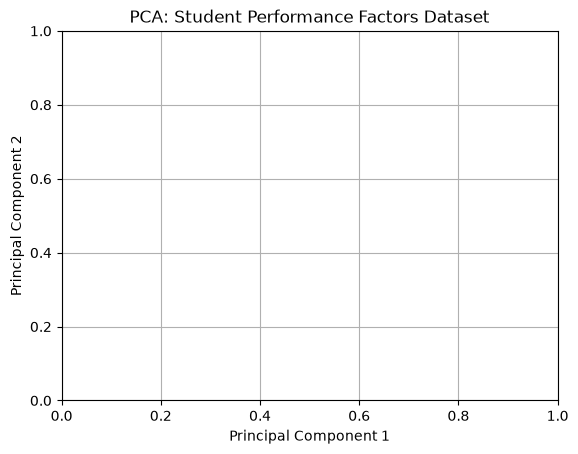

In [42]:
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Student Performance Factors Dataset")
plt.grid(True)
plt.show()

In [43]:
plt.figure(figsize=(7, 4))
components = ["PC1", "PC2"]

<Figure size 700x400 with 0 Axes>

<BarContainer object of 2 artists>

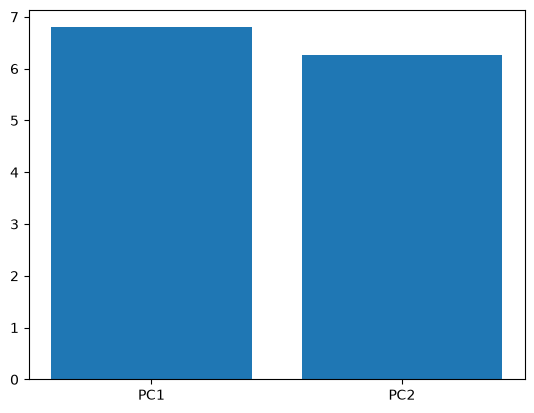

In [44]:
plt.bar(
    components,
    pca.explained_variance_ratio_ * 100
)

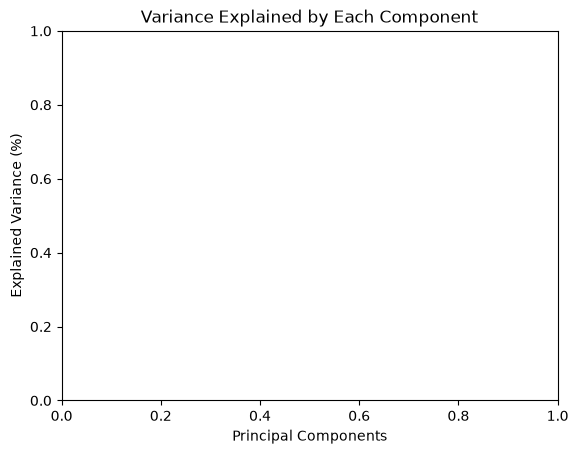

In [45]:
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("Variance Explained by Each Component")
plt.show()

In [46]:
print("\nOriginal Exam Scores:")
print(y.head())


Original Exam Scores:
0    67
1    61
2    74
3    71
4    70
Name: Exam_Score, dtype: int64


In [47]:
print("\nFeature Engineering Completed Successfully!")


Feature Engineering Completed Successfully!
